## Exploratory Data Analysis on Diabetes-130 dataset

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



In [3]:
#  reading the file
plt.style.use("seaborn-v0_8-whitegrid")

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "diabetes130" / "diabetic_data.csv"

assert DATA_PATH.exists(), f"File not found: {DATA_PATH}"

# Crucial: missing values in Diabetes 130-US hospitals are coded as "?"
df = pd.read_csv(DATA_PATH, na_values="?", low_memory=False)

print(f"Dataset shape: {df.shape[0]:,} encounters x {df.shape[1]} columns")
df.head(3)

Dataset shape: 101,766 encounters x 50 columns


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


 Readmitted Distribution 
            count    pct
readmitted              
NO          54864  53.91
>30         35545  34.93
<30         11357  11.16

Binary <30d positives: 11,357 (11.16%)

Unique patients (patient_nbr): 71,518
Patients with >1 encounter:    16,773 (23.5%)
Max encounters per patient:    40


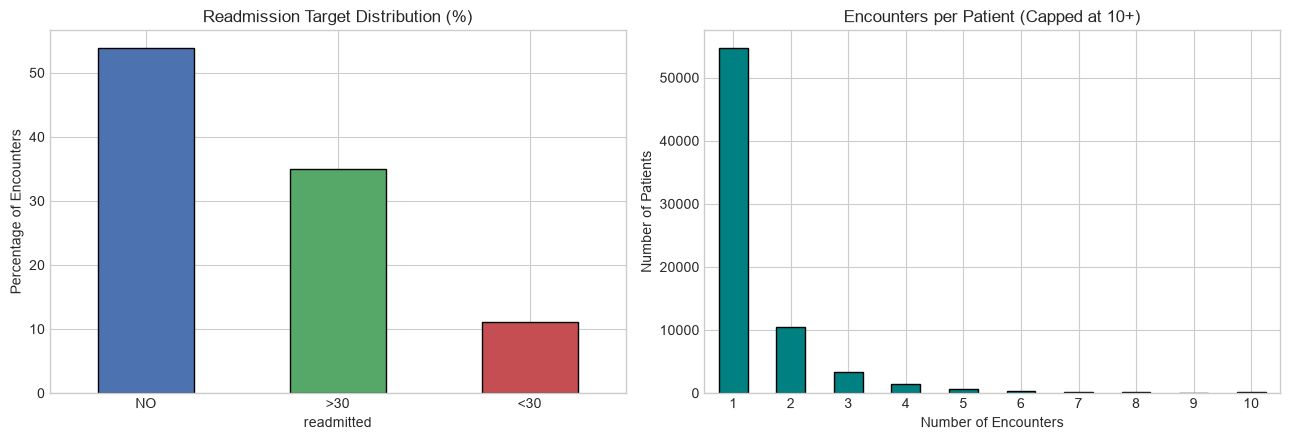

In [4]:
# Target distribution
readmit_counts = df["readmitted"].value_counts(dropna=False)
readmit_pct = (df["readmitted"].value_counts(normalize=True, dropna=False) * 100).round(2)

print(" Readmitted Distribution ")
print(pd.DataFrame({"count": readmit_counts, "pct": readmit_pct}))

# Binary target preview: <30 day readmission
y_30d = (df["readmitted"] == "<30").astype(int)
print(f"\nBinary <30d positives: {y_30d.sum():,} ({y_30d.mean() * 100:.2f}%)")

# Unique patients vs encounters
unique_patients = df["patient_nbr"].nunique()
encounters_per_patient = df.groupby("patient_nbr")["encounter_id"].count()
repeat_patients = int((encounters_per_patient > 1).sum())

print(f"\nUnique patients (patient_nbr): {unique_patients:,}")
print(f"Patients with >1 encounter:    {repeat_patients:,} ({repeat_patients / unique_patients * 100:.1f}%)")
print(f"Max encounters per patient:    {encounters_per_patient.max()}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
readmit_pct.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#55A868", "#C44E52"], edgecolor="black")
axes[0].set_title("Readmission Target Distribution (%)")
axes[0].set_ylabel("Percentage of Encounters")
axes[0].tick_params(axis="x", rotation=0)

encounters_per_patient.clip(upper=10).value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color="teal", edgecolor="black"
)
axes[1].set_title("Encounters per Patient (Capped at 10+)")
axes[1].set_xlabel("Number of Encounters")
axes[1].set_ylabel("Number of Patients")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

In [5]:
missing_df = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_pct": (df.isnull().mean() * 100).round(2),
    "nunique_non_null": df.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)

print(" Top 15 Columns by Missingness ")
display(missing_df.head(15))

# Check specific benchmarks
for col in ["weight", "max_glu_serum", "A1Cresult", "medical_specialty", "payer_code", "race"]:
    if col in df.columns:
        pct = df[col].isnull().mean() * 100
        print(f"{col:<20}: {pct:6.2f}% missing")

# Inspect A1Cresult categories (including missing = "Not Ordered")
print("\n A1Cresult Value Counts (with NaN) ")
print(df["A1Cresult"].fillna("NOT_ORDERED").value_counts())

 Top 15 Columns by Missingness 


,missing_count,missing_pct,nunique_non_null
weight,98569,96.86,9
max_glu_serum,96420,94.75,3
A1Cresult,84748,83.28,3
medical_specialty,49949,49.08,72
payer_code,40256,39.56,17
race,2273,2.23,5
diag_3,1423,1.40,789
diag_2,358,0.35,748
diag_1,21,0.02,716
encounter_id,0,0.00,101766


weight              :  96.86% missing
max_glu_serum       :  94.75% missing
A1Cresult           :  83.28% missing
medical_specialty   :  49.08% missing
payer_code          :  39.56% missing
race                :   2.23% missing

 A1Cresult Value Counts (with NaN) 
A1Cresult
NOT_ORDERED    84748
>8              8216
Norm            4990
>7              3812
Name: count, dtype: int64


In [6]:

# --- Death / hospice 
death_hospice_codes = {11, 13, 14, 19, 20, 21}
death_hospice_mask = df["discharge_disposition_id"].isin(death_hospice_codes)
print(f"Encounters ending in death/hospice (codes {sorted(death_hospice_codes)}): {death_hospice_mask.sum():,}")
print(df.loc[death_hospice_mask, "discharge_disposition_id"].value_counts())

# --- Invalid gender 
print(f"\nGender 'Unknown/Invalid' rows: {(df['gender'] == 'Unknown/Invalid').sum()}")

# --- Validating encounter_id as a time proxy
df_sorted = df.sort_values(["patient_nbr", "encounter_id"]).copy()
multi_patient_ids = encounters_per_patient[encounters_per_patient > 1].index
rep = df_sorted[df_sorted["patient_nbr"].isin(multi_patient_ids)].copy()

# Check 1: share of "NO" labels for last vs earlier encounters
rep["is_last"] = rep.groupby("patient_nbr").cumcount(ascending=False) == 0
no_rate = rep.groupby("is_last")["readmitted"].apply(lambda s: (s == "NO").mean() * 100).round(1)
print("\nCheck 1 — % labelled 'NO' (not readmitted), repeat patients only:")
print(f"  earlier encounters: {no_rate[False]}%")
print(f"  last encounter:     {no_rate[True]}%")
print("The last encounter to be much higher")

# Check 2: direction of change in number_inpatient between consecutive encounters
diff = rep.groupby("patient_nbr")["number_inpatient"].diff().dropna()
print("\nCheck 2 — number_inpatient from one encounter to the next (encounter_id order):")
print(f"  increases: {(diff > 0).mean() * 100:.1f}%")
print(f"  same:      {(diff == 0).mean() * 100:.1f}%")
print(f"  decreases: {(diff < 0).mean() * 100:.1f}%")
print("Observation: increases >> decreases (some decreases are normal: the counter only covers the past year)")

Encounters ending in death/hospice (codes [11, 13, 14, 19, 20, 21]): 2,423
discharge_disposition_id
11    1642
13     399
14     372
19       8
20       2
Name: count, dtype: int64

Gender 'Unknown/Invalid' rows: 3

Check 1 — % labelled 'NO' (not readmitted), repeat patients only:
  earlier encounters: 1.6%
  last encounter:     69.6%
The last encounter to be much higher

Check 2 — number_inpatient from one encounter to the next (encounter_id order):
  increases: 73.7%
  same:      16.4%
  decreases: 9.9%
Observation: increases >> decreases (some decreases are normal: the counter only covers the past year)


In [7]:
#Diagnosis Codes & Medication Column Cardinality / Near-Z

diag_cols = ["diag_1", "diag_2", "diag_3"]
all_diags = pd.concat([df[c] for c in diag_cols], ignore_index=True).dropna()
diag_counts = all_diags.value_counts()

rare_diag_pct = ((diag_counts <= 5).mean() * 100).round(2)
print(f"Distinct ICD-9 codes across diag_1..3: {len(diag_counts):,}")
print(f"ICD-9 codes appearing <= 5 times:     {(diag_counts <= 5).sum():,} ({rare_diag_pct}%)")

# Medication columns audit (columns from 'metformin' through 'citoglipton' or 'examide')
med_start = df.columns.get_loc("metformin")
med_end = df.columns.get_loc("change")
med_cols = list(df.columns[med_start:med_end])

med_summary = []
for col in med_cols:
    vc = df[col].value_counts(dropna=False)
    top_val = vc.index[0]
    top_pct = (vc.iloc[0] / len(df)) * 100
    n_unique = df[col].nunique(dropna=True)
    med_summary.append({
        "medication": col,
        "nunique_non_null": n_unique,
        "top_value": top_val,
        "top_pct": round(top_pct, 2),
    })

med_df = pd.DataFrame(med_summary).sort_values("top_pct", ascending=False)
print("\n Medication Columns (Most Dominant / Constant First) ")
display(med_df)

Distinct ICD-9 codes across diag_1..3: 915
ICD-9 codes appearing <= 5 times:     228 (24.92%)

 Medication Columns (Most Dominant / Constant First) 


,medication,nunique_non_null,top_value,top_pct
22,metformin-pioglitazone,2,No,100.00
21,metformin-rosiglitazone,2,No,100.00
20,glimepiride-pioglitazone,2,No,100.00
5,acetohexamide,2,No,100.00
16,citoglipton,1,No,100.00
15,examide,1,No,100.00
13,troglitazone,2,No,100.00
19,glipizide-metformin,2,No,99.99
8,tolbutamide,2,No,99.98
12,miglitol,4,No,99.96


In [8]:
# subgroup sizes for the fairness analysis in Phase 3.
# Small groups give wide confidence intervals on subgroup AUROC
eda = df.assign(y=(df["readmitted"] == "<30").astype(int))

for col in ["race", "gender", "age"]:
    t = (
        eda.groupby(col, dropna=False)["y"]
        .agg(encounters="size", pct_readmitted_30d="mean")
        .assign(pct_readmitted_30d=lambda x: (x["pct_readmitted_30d"] * 100).round(2))
    )
    print(f" {col} ")
    display(t)

print("Note: groups with only a few hundred encounters (e.g. Asian) will have wide subgroup CIs.")

 race 


,encounters,pct_readmitted_30d
race,,
AfricanAmerican,19210,11.22
Asian,641,10.14
Caucasian,76099,11.29
Hispanic,2037,10.41
Other,1506,9.63
NaN,2273,8.27


 gender 


,encounters,pct_readmitted_30d
gender,,
Female,54708,11.25
Male,47055,11.06
Unknown/Invalid,3,0.00


 age 


,encounters,pct_readmitted_30d
age,,
[0-10),161,1.86
[10-20),691,5.79
[20-30),1657,14.24
[30-40),3775,11.23
[40-50),9685,10.60
[50-60),17256,9.67
[60-70),22483,11.13
[70-80),26068,11.77
[80-90),17197,12.08


Note: groups with only a few hundred encounters (e.g. Asian) will have wide subgroup CIs.


 number_inpatient (prior-year inpatient visits, capped at 5) 
                  pct_30d      n
number_inpatient                
0                    8.44  67630
1                   12.92  19521
2                   17.43   7566
3                   20.29   3411
4                   23.61   1622
5                   36.41   2016 

 age bracket 
          pct_30d      n
age                     
[0-10)       1.86    161
[10-20)      5.79    691
[20-30)     14.24   1657
[30-40)     11.23   3775
[40-50)     10.60   9685
[50-60)      9.67  17256
[60-70)     11.13  22483
[70-80)     11.77  26068
[80-90)     12.08  17197
[90-100)    11.10   2793 

 A1C test ordered? 
             pct_30d      n
A1Cresult                  
not ordered    11.42  84748
ordered         9.85  17018 

 discharge_disposition_id (top 8) 
                          pct_30d      n
discharge_disposition_id                
1.0                          9.30  60234
2.0                         16.07   2128
3.0                    

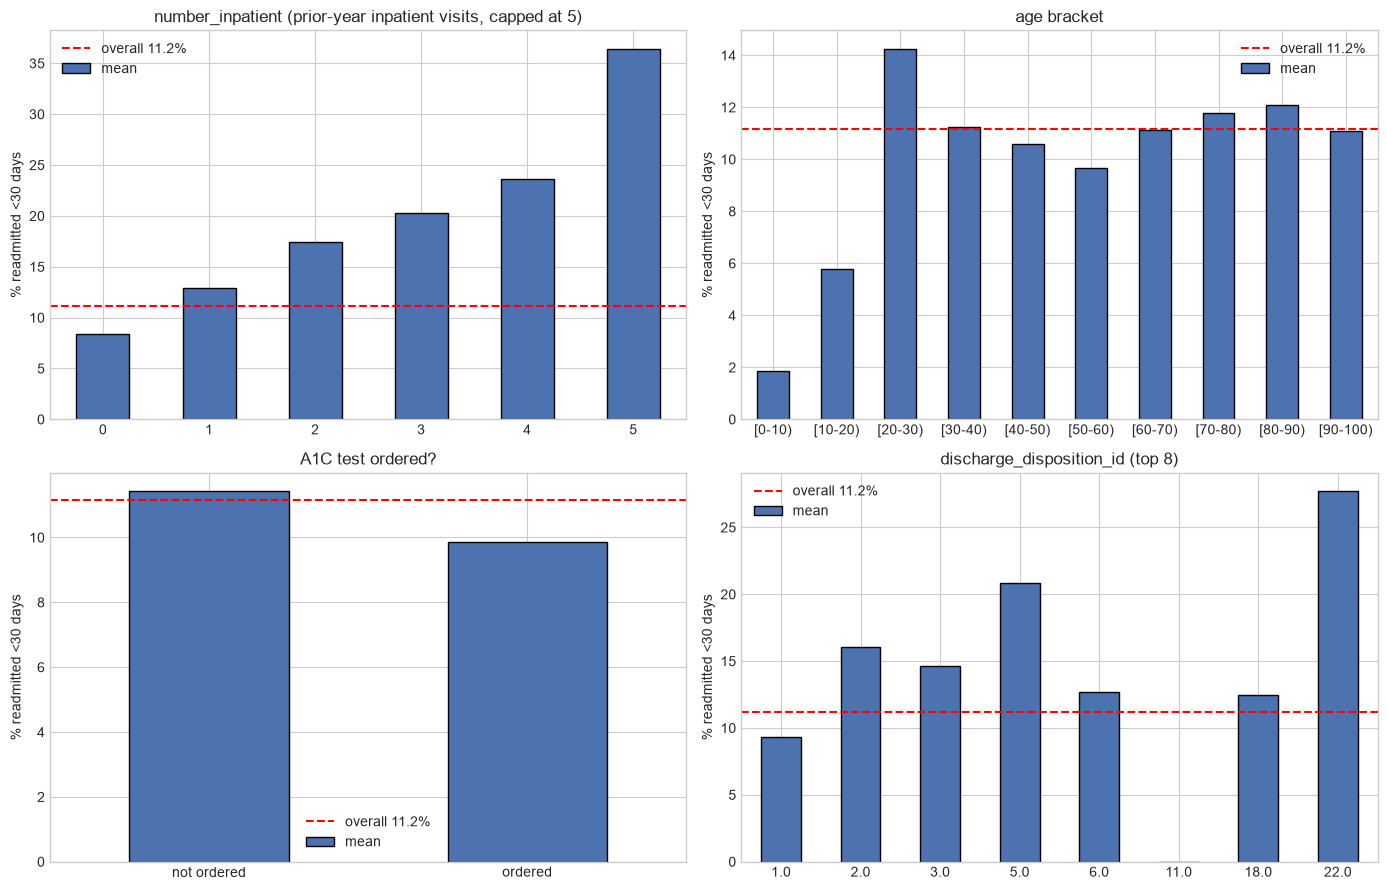

In [9]:

base_rate = eda["y"].mean() * 100

views = {
    "number_inpatient (prior-year inpatient visits, capped at 5)": eda["number_inpatient"].clip(upper=5),
    "age bracket": eda["age"],
    "A1C test ordered?": eda["A1Cresult"].notna().map({True: "ordered", False: "not ordered"}),
    "discharge_disposition_id (top 8)": eda["discharge_disposition_id"].where(
        eda["discharge_disposition_id"].isin(eda["discharge_disposition_id"].value_counts().index[:8])
    ),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (title, key) in zip(axes.ravel(), views.items()):
    rate = eda.groupby(key)["y"].agg(["mean", "size"])
    (rate["mean"] * 100).plot(kind="bar", ax=ax, color="#4C72B0", edgecolor="black")
    ax.axhline(base_rate, color="red", linestyle="--", label=f"overall {base_rate:.1f}%")
    ax.set_title(title)
    ax.set_ylabel("% readmitted <30 days")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.legend()
    print(f" {title} ")
    print(rate.assign(mean=lambda x: (x["mean"] * 100).round(2)).rename(columns={"mean": "pct_30d", "size": "n"}), "\n")

plt.tight_layout()
plt.show()

## Findings → Decisions

| # | Finding | Decision for Phase 2+ |
|---|---|---|
| 1 | 101,766 encounters; `<30` = **11.16%** of encounters | Label = `readmitted == "<30"`. Report AUPRC (random baseline ≈ 0.11) and calibration, not accuracy |
| 2 | 71,518 patients; 16,773 (23.5%) have more than one encounter, up to 40 | **Split by patient** (`StratifiedGroupKFold`), never by encounter |
| 3 | 2,423 encounters end in death or hospice; 3 rows have gender `Unknown/Invalid` | Drop both |
| 4 | `weight` 96.9% missing; `examide`, `citoglipton` constant; several other drugs ~100% "No" | Drop `weight`, `examide`, `citoglipton`. Near-constant drugs: keep for now and let the train-split frequency filter decide in Phase 3 |
| 5 | `A1Cresult` 83% missing = test not ordered; same for `max_glu_serum` | Keep "not ordered" as its own category. Do not impute |
| 6 | `medical_specialty` 49% missing (72 values), `payer_code` 40% missing | Keep "missing" as a category; group rare specialties into "other" |
| 7 | Time proxy: last encounter "NO" rate = 69.6% vs earlier = 1.6%; `number_inpatient` increases 73.7% vs decreases 9.9% | `encounter_id` order hold up as a time proxy. Graph edges go from earlier to later encounters only |
| 8 | 915 distinct ICD-9 codes; 228 (24.9%) appear ≤ 5 times | Rare-code analysis is worth doing. **In Phase 3+, count rarity on the train split only**, otherwise test data leaks into the buckets |
| 9 | Subgroups: Asian: 641 encounters, under-20yo, "Other" race and missing race | Report subgroup AUROC with CIs; flag small groups as low-confidence |
| 10 | Signal:  `number_inpatient` seem to move the rate most | Expect these near the top of SHAP in Phase 3 |